# 070 CASE 030 — Marine vessels: Sotenäs

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** How many vessels can a free 10 m satellite image show along the Bohuslän coast on a summer day?

**Area:** The sea off Sotenäs (Smögen, Kungshamn, Hunnebostrand), Bohuslän, 16 August 2024.

**Partners:** SSC, Swedish Maritime Administration (Sjöfartsverket), PandionAI, RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Copernicus Sentinel-2 data are free and open. The YOLO11s vessel model ([mayrajeo/marine-vessel-yolo](https://huggingface.co/mayrajeo/marine-vessel-yolo)) and Ultralytics are **AGPL-3.0**; closed-source commercial use needs an Ultralytics licence.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus the plotting libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1a" folium matplotlib sahi ultralytics
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own
DES account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password. The login is yours: no credentials are shared or saved in the notebook. Without a login the data fetch stops with an error; there is no synthetic
fallback, so every figure comes from real Sentinel-2 data. A run takes two to four minutes on a laptop CPU.

## Log in to Digital Earth Sweden

In [ ]:
import os
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    os.environ["DES_USER"] = input("DES username: ")
    os.environ["DES_PASSWORD"] = getpass("DES password: ")
    des.authenticate_basic(os.environ["DES_USER"], os.environ["DES_PASSWORD"])
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires


def des_token():
    """Your EGI login's access token; with a password login IMINT Engine reads DES_USER/DES_PASSWORD."""
    return des.auth.bearer.split("/", 2)[2] if LOGIN_METHOD == "egi" else None


## 1. Method

```
AOI + date → fetch_des_data → MarineVesselAnalyzer (YOLO11s on true-colour tiles, SAHI slicing) → boxes
```

`MarineVesselAnalyzer` runs a YOLO11s model trained on Sentinel-2 true-colour imagery over sliced
tiles (SAHI) and masks land with the scene classification. At 10 m resolution a vessel must be
roughly 20 m or longer to be seen; small boats and vessels next to quays are often missed.

## 2. Area and data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud, token=des_token())
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 11.05, "south": 58.30, "east": 11.30, "north": 58.45}
DATE = "2024-08-16"

scene = load_scene(DATE, AOI)

    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 0.0%
2024-08-16: 11 bands, 1752 x 1557 px at 10 m, cloud 0.0% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#0066ff", weight=2, fill=False, popup="AOI",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Detect vessels

In [4]:
from imint.analyzers.marine_vessels import MarineVesselAnalyzer

vessels = MarineVesselAnalyzer().run(rgb=scene.rgb, bands=scene.bands, date=DATE, coords=AOI,
                                     output_dir="outputs/vessels", scl=scene.scl, geo=scene.geo)
print(vessels.summary())
out = vessels.outputs
print(f"vessels detected: {out['vessel_count']}")
print(f"density: {out['vessel_density_per_km2']} per km²")
scores = [r["score"] for r in out.get("regions", [])]
if scores:
    print(f"confidence: median {np.median(scores):.2f}, min {min(scores):.2f}")

[marine_vessels] OK — outputs: regions, vessel_count, vessel_density_per_km2
vessels detected: 19
density: 0.07 per km²
confidence: median 0.51, min 0.31


## 4. Results

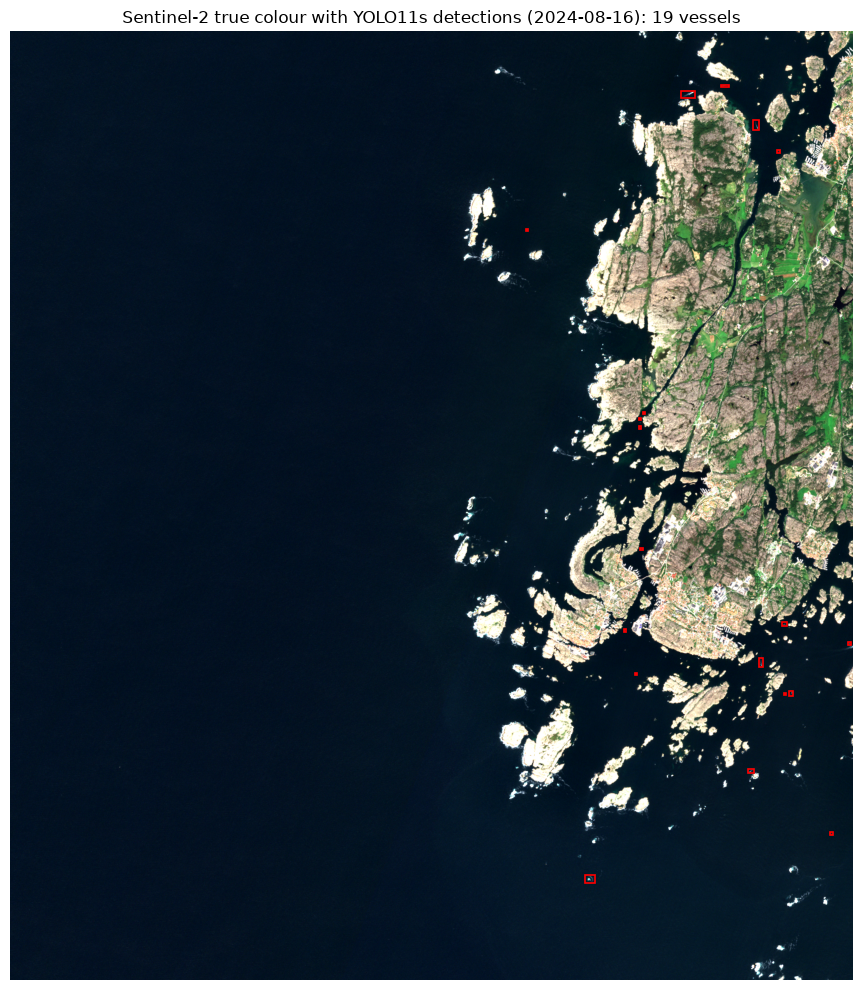

In [5]:
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(scene.rgb)
for r in out.get("regions", []):
    bb = r["bbox"]
    ax.add_patch(mpatches.Rectangle((bb["x_min"], bb["y_min"]), bb["x_max"] - bb["x_min"],
                                    bb["y_max"] - bb["y_min"], linewidth=1.2,
                                    edgecolor="red", facecolor="none"))
ax.set_title(f"Sentinel-2 true colour with YOLO11s detections ({DATE}): {out['vessel_count']} vessels")
ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

The detections are candidates, not identified ships: a box can be a boat, a buoy cluster or wake.
Sentinel-2 passes about every two to three days, so it suits statistics over time better than
tracking. Comparing with AIS shows which detected vessels were not transmitting.

**Next steps:** run several dates to build a density map, or compare with AIS for the same overpass.

**Links:** [`imint/analyzers/marine_vessels.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/marine_vessels.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).